# Binaural rendering from measured HRIRs

Places a mono recording at a chosen direction by convolving it with one listener's measured head-related impulse responses (HRIRs):

1. Load an HRIR set stored in the SOFA format.
2. Find the measured direction nearest the one requested.
3. Resample the source to the HRIR sampling rate and convolve it with the left- and right-ear HRIRs.
4. Normalize both ears with one gain, so the level difference between them is kept, and write a stereo WAV for headphones.

Built with [pyfar](https://pyfar.org) and [sofar](https://sofar.readthedocs.io).

## Setup

The HRIRs come from Meta Reality Labs' SS2 database (listener YNB205, 1,625 directions, 48 kHz, CC-BY-4.0). Put the SOFA file and a mono source recording in `data/`; neither is committed to this repo. Renders are written to `renders/`.

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyfar as pf
import sofar as sf

DATA = Path("data")
SOFA_FILE = "YNB205081622_1_processed.sofa"
SOURCE_FILE = "trumpet.wav"
OUT = Path("renders")
OUT.mkdir(exist_ok=True)

## Inspect the HRIR set

In [6]:
sofa = sf.read_sofa(SOFA_FILE, verbose=False)
print(f"{sofa.GLOBAL_SOFAConventions} | {sofa.GLOBAL_DatabaseName} | listener {sofa.GLOBAL_ListenerShortName}")
print(f"{sofa.Data_IR.shape[0]} directions, {sofa.Data_IR.shape[2]} taps, {sofa.Data_SamplingRate:.0f} Hz")
print("Receiver positions (m):")
print(np.squeeze(sofa.ReceiverPosition))

SimpleFreeFieldHRIR | Meta SS2 | listener YNB205
1625 directions, 384 taps, 48000 Hz
Receiver positions (m):
[[ 0.    0.09  0.  ]
 [ 0.   -0.09  0.  ]]


In SOFA's coordinate system +y points to the listener's left, so the receiver at y = +0.09 m is the left ear. pyfar keeps the file's order, so channel 0 is the left ear; the assert guards against a file that stores them the other way round.

In [7]:
hrirs, sources, receivers = pf.io.read_sofa(SOFA_FILE, verbose=False)
assert receivers.y[0] > receivers.y[1], "Expected the left ear in channel 0"
hrirs

time domain energy Signal:
(1625, 2) channels with 384 samples @ 48000.0 Hz sampling rate and none FFT normalization

## Pick a direction

Azimuth runs counterclockwise from straight ahead (90° is the listener's left); elevation is measured up from the horizontal plane. The set only holds measured directions, so the nearest one is used and reported.

In [8]:
def nearest_hrir(azimuth_deg, elevation_deg):
    target = pf.Coordinates.from_spherical_elevation(
        np.radians(azimuth_deg), np.radians(elevation_deg), sources.radius.mean())
    index, _ = sources.find_nearest(target)
    found = sources[index]
    print(f"requested az {azimuth_deg:5.1f}°, el {elevation_deg:5.1f}°  ->  "
          f"measured az {np.degrees(found.azimuth).item():5.1f}°, el {np.degrees(found.elevation).item():5.1f}°")
    return hrirs[index].flatten()

hrir = nearest_hrir(25, 0)

requested az  25.0°, el   0.0°  ->  measured az  24.0°, el   0.0°


## Look at the pair

At 25° to the left, the left ear's response arrives first and louder. The right ear's arrives later (interaural time difference) and with less high-frequency energy, because the head shadows it.

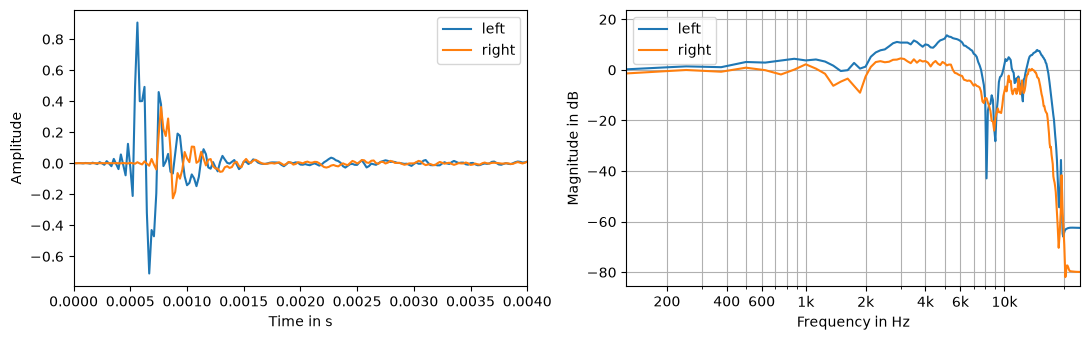

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ch, name in enumerate(["left", "right"]):
    pf.plot.time(hrir[ch], ax=axes[0], label=name)
    pf.plot.freq(hrir[ch], ax=axes[1], label=name)
axes[0].set_xlim(0, 0.004)
axes[0].legend()
axes[1].legend()
plt.tight_layout()

## Render

In [10]:
source = pf.io.read_audio(SOURCE_FILE)
if source.cshape != (1,):  # mix multichannel recordings down to mono
    source = pf.Signal(source.time.mean(axis=0, keepdims=True), source.sampling_rate)
if source.sampling_rate != hrirs.sampling_rate:
    source = pf.dsp.resample(source, hrirs.sampling_rate)


def render(azimuth_deg, elevation_deg, name):
    binaural = pf.dsp.convolve(source, nearest_hrir(azimuth_deg, elevation_deg))
    # One gain for both ears keeps the interaural level difference; peak at -1 dBFS avoids clipping.
    binaural = pf.dsp.normalize(binaural, channel_handling="max", target=10 ** (-1 / 20))
    path = OUT / f"{name}.wav"
    pf.io.write_audio(binaural, path)
    print(f"  wrote {path}")
    return binaural


for name, azimuth in [("front", 0), ("left_25", 25), ("left", 90), ("back", 180), ("right", 270)]:
    render(azimuth, 0, name)

requested az   0.0°, el   0.0°  ->  measured az   0.0°, el   0.0°
  wrote renders/front.wav
requested az  25.0°, el   0.0°  ->  measured az  24.0°, el   0.0°
  wrote renders/left_25.wav
requested az  90.0°, el   0.0°  ->  measured az  90.0°, el   0.0°
  wrote renders/left.wav
requested az 180.0°, el   0.0°  ->  measured az 180.0°, el   0.0°
  wrote renders/back.wav
requested az 270.0°, el   0.0°  ->  measured az 270.0°, el   0.0°
  wrote renders/right.wav


## Listening

Listen on headphones. These HRIRs belong to one person, so for other listeners the renders often sound inside the head, or front and back get confused. Closing that gap is the goal of HRTF individualization.